# 📘 Notebook 02: Epochs and Early Stopping, How Long to Train

### Course: *From Defaults to Decisions: Hyperparameters, Explained by Experiment*
**Instructor:** Ioannis Tsioulis

---

> 💡 **This notebook is already run.** Every number and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** About **ten minutes** on an ordinary processor. Small networks on 10,000 images; the best number of epochs found here belongs to this data and model, while the shape of the curves is general.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Define an **epoch** and read **learning curves** of training and validation loss
- Recognise **underfitting** and **overfitting** from those curves
- Explain why a **bigger** network overfits **sooner**
- Implement **early stopping** with a **patience** and restore the best weights
- Explain why the validation **loss** and the validation **accuracy** can disagree

> **Prerequisites:** [Notebook 01](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-defaults-to-decisions/01_what_is_a_hyperparameter.ipynb).
>
> 🔭 **Why this notebook matters:** "how many epochs?" is the first question everyone asks, and the honest answer is "until the validation curve says stop". Early stopping is the cheapest and most widely used protection against overfitting, and reading learning curves is the most useful skill for every later notebook.

In [1]:
# Shared setup: the same data, model builder and training loop in every notebook of this course.
import warnings
warnings.filterwarnings("ignore")

import gzip, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.precision", 3)

BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(BASE + name).read()), dtype=np.uint8, offset=header)

images = torch.tensor(read_idx("train-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
labels = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)
X_test = torch.tensor(read_idx("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
y_test = torch.tensor(read_idx("t10k-labels-idx1-ubyte.gz", 8), dtype=torch.long)
mean, std = images.mean(), images.std()
images, X_test = (images - mean) / std, (X_test - mean) / std

order = torch.randperm(len(images), generator=torch.Generator().manual_seed(0))
X_train, y_train = images[order[:10000]], labels[order[:10000]]       # 10,000 images to learn from
X_val, y_val = images[order[10000:15000]], labels[order[10000:15000]] # 5,000 to choose hyperparameters
print(f"train {len(X_train):,}   validation {len(X_val):,}   test {len(X_test):,}")

def make_mlp(hidden=(128,), activation=nn.ReLU, dropout=0.0, batchnorm=False):
    layers, width = [], 784
    for h in hidden:
        layers.append(nn.Linear(width, h))
        if batchnorm:
            layers.append(nn.BatchNorm1d(h))
        layers.append(activation())
        if dropout:
            layers.append(nn.Dropout(dropout))
        width = h
    layers.append(nn.Linear(width, 10))
    return nn.Sequential(*layers)

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def fit(model, epochs=20, lr=1e-3, batch=128, optimizer="adam", weight_decay=0.0, scheduler=None, seed=0, X=None, y=None):
    """Train and return a history with one row per epoch."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    torch.manual_seed(seed)
    opts = {"sgd": lambda p: torch.optim.SGD(p, lr=lr, weight_decay=weight_decay),
            "momentum": lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=weight_decay),
            "rmsprop": lambda p: torch.optim.RMSprop(p, lr=lr, weight_decay=weight_decay),
            "adam": lambda p: torch.optim.Adam(p, lr=lr, weight_decay=weight_decay),
            "adamw": lambda p: torch.optim.AdamW(p, lr=lr, weight_decay=weight_decay)}
    opt = opts[optimizer](model.parameters())
    steps_per_epoch = (len(X) + batch - 1) // batch
    sched = scheduler(opt, epochs * steps_per_epoch) if scheduler else None
    rows, start = [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X))
        total = 0.0
        for i in range(0, len(X), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            if sched:
                sched.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = F.cross_entropy(model(X_val), y_val).item()
        rows.append({"epoch": epoch, "train loss": total / len(X), "val loss": val_loss,
                     "train acc": accuracy(model, X, y), "val acc": accuracy(model, X_val, y_val)})
    history = pd.DataFrame(rows).set_index("epoch")
    history.attrs["seconds"] = time.time() - start
    return history

train 10,000   validation 5,000   test 10,000


## 1. What is an epoch?

### Intuition first
One **epoch** is one full pass over the training set. With 10,000 images and batches of 128, one epoch is 79 updates of the weights. More epochs give the network more chances to learn, and also more chances to **memorise** the training images instead of learning general patterns.

We train a network with one hidden layer of 128 neurons for 60 epochs and watch both sets.

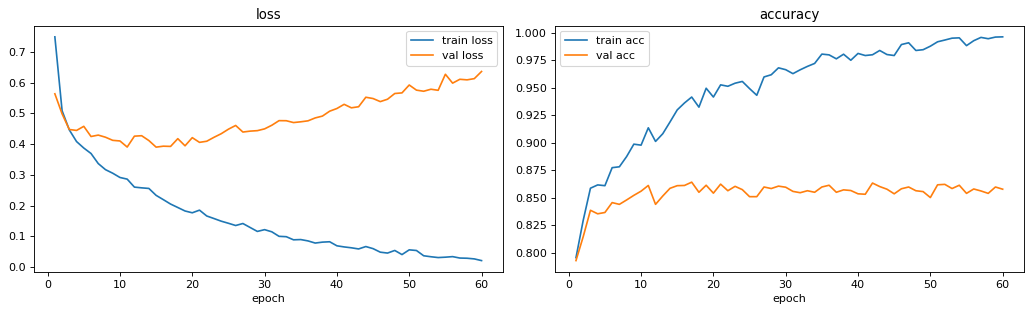

lowest validation loss at epoch 15: 0.390   at epoch 60: 0.636
validation accuracy at epoch 15: 0.8610   best ever: 0.8642 (epoch 17)   at epoch 60: 0.8578
training accuracy at epoch 60: 0.9965


In [2]:
history = fit(make_mlp(hidden=(128,)), epochs=60)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
history[["train loss", "val loss"]].plot(ax=axes[0], title="loss")
history[["train acc", "val acc"]].plot(ax=axes[1], title="accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
plt.tight_layout()
plt.show()
best_epoch = int(history["val loss"].idxmin())
print(f"lowest validation loss at epoch {best_epoch}: {history['val loss'].min():.3f}   at epoch 60: {history['val loss'].iloc[-1]:.3f}")
print(f"validation accuracy at epoch {best_epoch}: {history['val acc'].loc[best_epoch]:.4f}   best ever: {history['val acc'].max():.4f} (epoch {int(history['val acc'].idxmax())})   at epoch 60: {history['val acc'].iloc[-1]:.4f}")
print(f"training accuracy at epoch 60: {history['train acc'].iloc[-1]:.4f}")

**What we see.** The two curves tell different stories. The **training** loss falls all the way (training accuracy reaches **99.7%** at epoch 60: the network has memorised almost every training image). The **validation** loss falls until about epoch **15** (0.390) and then **rises** steadily, to **0.636** at epoch 60. That rise is overfitting.

Notice, however, that validation **accuracy** barely suffers: 86.1% at epoch 15, a best of 86.4% at epoch 17, still 85.8% at epoch 60. The loss rises because the network becomes **over-confident**: on the images it gets wrong, it is now very sure of the wrong answer, which the loss punishes heavily while accuracy only counts right or wrong. The loss gives the earlier and clearer warning.

## 2. Underfitting, a good fit, overfitting

The same picture can be read in three phases:
- **Underfitting** (early epochs): both losses are high and falling; the model has not learned enough yet. More epochs help.
- **A good fit** (around the best epoch): the validation loss is at its lowest.
- **Overfitting** (later): the training loss keeps falling, the validation loss rises. The gap between them is the model memorising the training images.

How soon overfitting starts depends on the **capacity** of the model. We compare three widths.

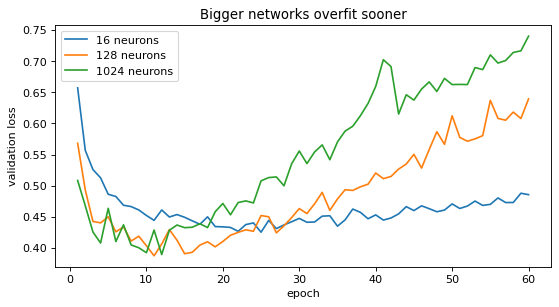

,16 neurons,128 neurons,1024 neurons
best epoch (val loss),25.000,11.000,12.000
lowest val loss,0.425,0.387,0.389
val loss at 60,0.486,0.639,0.740
best val acc,0.849,0.863,0.871
train acc at 60,0.931,0.995,1.000


In [3]:
curves = {}
for width in [16, 128, 1024]:
    curves[width] = fit(make_mlp(hidden=(width,)), epochs=60)
fig, ax = plt.subplots(figsize=(8, 4))
for width, h in curves.items():
    ax.plot(h.index, h["val loss"], label=f"{width} neurons")
ax.set_xlabel("epoch"); ax.set_ylabel("validation loss"); ax.legend(); ax.set_title("Bigger networks overfit sooner")
plt.show()
pd.DataFrame({f"{w} neurons": {"best epoch (val loss)": int(h["val loss"].idxmin()), "lowest val loss": h["val loss"].min(),
                              "val loss at 60": h["val loss"].iloc[-1], "best val acc": h["val acc"].max(),
                              "train acc at 60": h["train acc"].iloc[-1]} for w, h in curves.items()}).round(3)

**What we see.** Capacity changes the timing and the size of overfitting:
- **16 neurons**: the validation loss reaches its lowest point late (epoch **25**) and rises only a little (0.425 to 0.486). Training accuracy stays at 93%: this small network cannot memorise everything.
- **128 neurons**: lowest at epoch **11**, then a clear rise to 0.639.
- **1,024 neurons**: lowest at epoch **12**, and the steepest rise of all (to **0.740**), with **100%** training accuracy.

Yet the largest network also reaches the **best** validation accuracy at its peak (**87.1%** against 86.3% and 84.9%). A big network is not bad in itself; it is bad if trained too long. That is exactly what early stopping fixes.

## 3. Early stopping

### Intuition first
We do not know the best epoch in advance, but we can watch for it. **Early stopping**: after every epoch, check the validation loss; remember the best weights so far; if the validation loss has not improved for **patience** epochs in a row, stop and go back to the best weights.

In [4]:
import copy

def fit_early_stopping(model, max_epochs=200, patience=5, lr=1e-3, batch=128, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_loss, best_state, best_epoch, waited = float("inf"), None, 0, 0
    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(len(X_train))
        for i in range(0, len(X_train), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(X_train[idx]), y_train[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            val_loss = F.cross_entropy(model(X_val), y_val).item()
        if val_loss < best_loss:
            best_loss, best_state, best_epoch, waited = val_loss, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            waited += 1
            if waited >= patience:
                break
    model.load_state_dict(best_state)
    return best_epoch, epoch

rows = {}
for patience in [1, 3, 5, 10, 20]:
    model = make_mlp(hidden=(1024,))
    best_epoch, stopped = fit_early_stopping(model, patience=patience)
    rows[patience] = {"stopped after": stopped, "best epoch kept": best_epoch,
                      "val acc": accuracy(model, X_val, y_val), "test acc": accuracy(model, X_test, y_test)}
untouched = make_mlp(hidden=(1024,)); fit(untouched, epochs=60)
rows["no early stopping (60 epochs)"] = {"stopped after": 60, "best epoch kept": 60,
                                         "val acc": accuracy(untouched, X_val, y_val), "test acc": accuracy(untouched, X_test, y_test)}
pd.DataFrame(rows).T.rename_axis("patience").round(4)

,stopped after,best epoch kept,val acc,test acc
patience,,,,
1,5.0,4.0,0.853,0.844
3,7.0,4.0,0.852,0.844
5,17.0,12.0,0.867,0.861
10,20.0,10.0,0.863,0.853
20,30.0,10.0,0.862,0.857
no early stopping (60 epochs),60.0,60.0,0.868,0.860


**What we see.** For the 1,024-neuron network:
- **Patience 1 or 3** stops far too early (after 5 or 7 epochs), keeping the weights of epoch 4: test accuracy **84.4%**. A single noisy epoch was mistaken for the end of learning.
- **Patience 5** stops after 17 epochs, keeping epoch 12: test accuracy **86.1%**, the best of all.
- **Patience 10 and 20** keep epoch 10 and reach 85.3% and 85.7%; the exact best epoch varies a little with noise.
- **No early stopping** (60 epochs) reaches **86.0%** test accuracy, close to the best, because accuracy suffered little from overfitting here (Section 1), but it took more than three times as long, and its probabilities are badly over-confident.

A patience of about 5 epochs gave the best result at a fraction of the cost. The differences between patience 5, 10 and 20 (under one point) are within the seed-to-seed spread of Notebook 01.

## ⚠️ Common pitfalls

- **Choosing the number of epochs on the test set.** Early stopping uses the validation set; the test set stays untouched.
- **Stopping without restoring the best weights.** The last weights come `patience` epochs **after** the best ones.
- **Watching only accuracy.** Validation accuracy is noisy and can stay flat while the loss already shows overfitting (Section 1).
- **A patience that is too small.** One bad epoch is often noise; stopping at the first rise can stop far too early.
- **Concluding that a model "needs" 60 epochs because a tutorial said so.** The right number depends on model size, data size, learning rate and batch size; it must be measured.

## ✏️ Exercises

### Exercise 1 (More data, later overfitting)
Train the 1024-neuron network for 60 epochs on only the **first 2,000** training images. At which epoch is the validation loss lowest, compared with 10,000 images?

In [5]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
h_small = fit(make_mlp(hidden=(1024,)), epochs=60, X=X_train[:2000], y=y_train[:2000])
print("2,000 images: best epoch", int(h_small["val loss"].idxmin()), " lowest val loss", round(h_small["val loss"].min(), 3))
print("10,000 images: best epoch", int(curves[1024]["val loss"].idxmin()), " lowest val loss", round(curves[1024]["val loss"].min(), 3))
```

*With fewer images, a large network memorises them sooner (in fewer updates), and its best validation loss is worse. The best number of epochs depends on the data as much as on the model.*
</details>

### Exercise 2 (Stop on accuracy instead of loss)
Change `fit_early_stopping` so that it watches validation **accuracy** (higher is better) instead of loss, with patience 5, and compare the epoch it stops at and the test accuracy.

In [6]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
def fit_es_acc(model, max_epochs=200, patience=5, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    best, best_state, best_epoch, waited = -1, None, 0, 0
    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(len(X_train))
        for i in range(0, len(X_train), 128):
            idx = perm[i:i + 128]
            loss = F.cross_entropy(model(X_train[idx]), y_train[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        acc = accuracy(model, X_val, y_val)
        if acc > best:
            best, best_state, best_epoch, waited = acc, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            waited += 1
            if waited >= patience:
                break
    model.load_state_dict(best_state)
    return best_epoch

m = make_mlp(hidden=(1024,))
print("best epoch by accuracy:", fit_es_acc(m), " test acc", round(accuracy(m, X_test, y_test), 4))
```

*In our run both rules kept the same epoch (12), with 85.9% test accuracy. That is not guaranteed: accuracy can keep improving a little after the loss has started to rise (the model still gets borderline images right while becoming over-confident on others), so stopping on accuracy sometimes runs longer, and it is noisier. Both are reasonable; loss is smoother, accuracy is what you report.*
</details>

## 🔑 Key takeaways

- One **epoch** is one pass over the training data; the right number is **measured**, not guessed.
- **Learning curves** show underfitting (both losses high), a good fit (validation loss lowest) and overfitting (validation loss rising while training loss falls).
- **Bigger** networks and **smaller** datasets overfit **sooner**.
- **Early stopping** with a patience of a few epochs, restoring the best weights, removes most of the guesswork.

---
**Next:** *Notebook 03: The Learning Rate*, the hyperparameter that matters most.

---
*© Ioannis Tsioulis. *From Defaults to Decisions: Hyperparameters, Explained by Experiment*. Prepared for educational use.*